# 020 — MLP 017 com dropout

Parte da configuração exata do 017: arquitetura 64→32, ReLU, Adam `lr=0.0001`, `weight_decay=0`, `batch_size=128`, ponderação normalizada 1/√frequência e até 100 épocas. Só varia dropout 0, 0.1 ou 0.2, após cada ReLU oculta. Cada execução reinicia rede, otimizador, gerador de minibatches e sementes a 42. Seleciona a primeira melhor época interna de cada opção e escolhe dropout por Macro F1 interna.

## Protocolo comum

Divisão estratificada fixa 80/20 (`random_state=42`) e validação interna estratificada de 15% dos 80% de treino (`random_state=42`), como nas experiências anteriores. A preparação é ajustada só nas linhas de treino de cada fase e os pesos de classe são calculados só nos respetivos alvos de treino. Todas as escolhas usam Macro F1 interna. A validação fixa já foi consultada em várias experiências; serve apenas como comparação de desenvolvimento, não como avaliação final independente.

Para a submissão, reajustam-se a preparação e modelos novos nas 10.962 linhas rotuladas, recalculando pesos de classe e usando as épocas escolhidas internamente. O CSV copia `RowId` do exemplo oficial na ordem das 3.655 linhas de teste e valida cabeçalho, unicidade, classes inteiras 0–15 e `index=False`.


Mostra curvas internas de perda e Macro F1 por época. CSV: `submissions/submission_020_mlp_dropout.csv`. A pontuação Kaggle fica em branco até ser submetido.

,Dropout,Melhor época,Macro F1 interna,Selecionada
0,0.0,75,0.4927,False
1,0.1,85,0.5020,True
2,0.2,90,0.4983,False


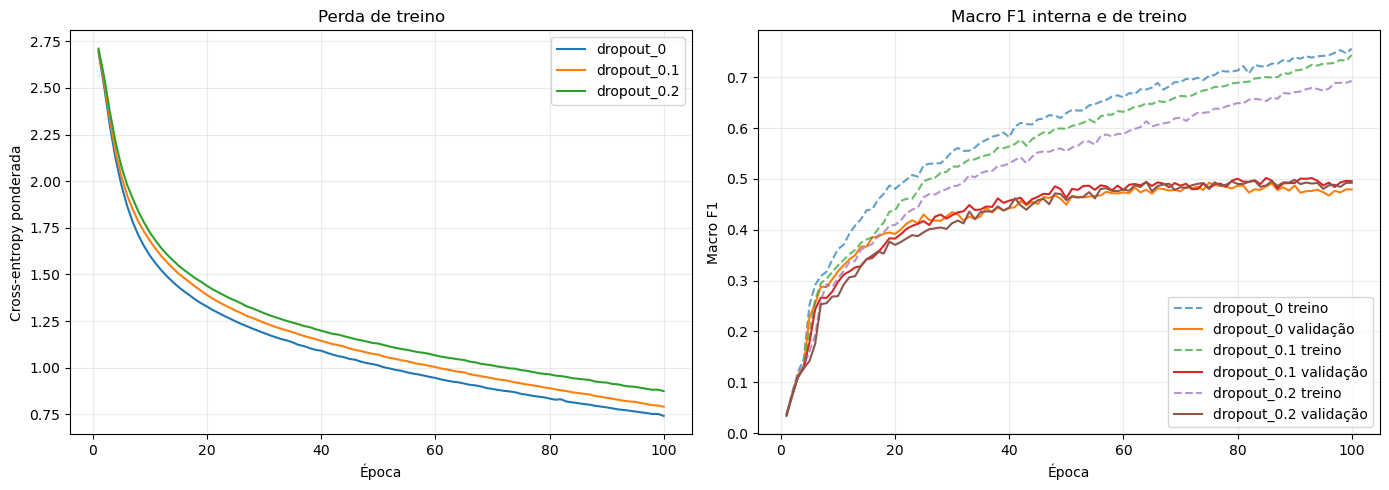

Modelo selecionado — validação fixa
Macro F1: 0.4454 | accuracy: 0.4441


,Classe,Escalão,F1,Recall,Suporte
0,0,15–17 anos,0.6905,0.7073,41
1,1,18–19 anos,0.4706,0.4706,34
2,2,20–24 anos,0.4967,0.4750,80
3,3,25–29 anos,0.3444,0.3467,75
4,4,30–34 anos,0.3280,0.3444,90
5,5,35–39 anos,0.3684,0.3798,129
6,6,40–44 anos,0.3818,0.3663,172
7,7,45–49 anos,0.3818,0.3642,173
8,8,50–54 anos,0.6174,0.6464,181
9,9,55–59 anos,0.6150,0.5862,203


Configuração selecionada: MLP 64→32, ReLU + Dropout(0.1), Adam lr=0.0001, pesos 1/sqrt(frequência), época=85
Diferença Macro F1 fixa vs. 017 (0.4351): +0.0103
Repete a configuração do 017 (dropout=0): False
Previsões diferentes do CSV 017: 591 / 3655; duplicado: False
CSV: submissions/submission_020_mlp_dropout.csv


In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display

repo_root = next(p for p in [Path.cwd(), *Path.cwd().resolve().parents]
                 if (p / "src" / "experiments_019_021.py").is_file())
sys.path.insert(0, str(repo_root))
import matplotlib.pyplot as plt
from src.experiments_019_021 import run_020

output = run_020()
result, histories = output["result"], output["histories"]
candidates = pd.DataFrame(result["candidates"])
candidates["Selecionada"] = candidates["dropout"] == result["selected"]["dropout"]
display(candidates[["dropout", "best_epoch", "internal_macro_f1", "Selecionada"]].rename(
    columns={"dropout": "Dropout", "best_epoch": "Melhor época", "internal_macro_f1": "Macro F1 interna"}
).style.format({"Dropout": "{:.1f}", "Macro F1 interna": "{:.4f}"}))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for label, history in histories.items():
    axes[0].plot(history["epoch"], history["train_loss"], label=label)
    axes[1].plot(history["epoch"], history["train_macro_f1"], linestyle="--", alpha=0.7, label=f"{label} treino")
    axes[1].plot(history["epoch"], history["validation_macro_f1"], label=f"{label} validação")
axes[0].set(title="Perda de treino", xlabel="Época", ylabel="Cross-entropy ponderada")
axes[1].set(title="Macro F1 interna e de treino", xlabel="Época", ylabel="Macro F1")
for axis in axes:
    axis.legend()
    axis.grid(alpha=0.25)
plt.tight_layout()
plt.show()
def show_metrics(metrics, title):
    print(title)
    print(f"Macro F1: {metrics['macro_f1']:.4f} | accuracy: {metrics['accuracy']:.4f}")
    per_band = pd.DataFrame(metrics["per_class"]).rename(
        columns={"classe": "Classe", "escalão": "Escalão", "F1": "F1", "recall": "Recall", "support": "Suporte"}
    )
    display(per_band.style.apply(
        lambda row: ["background-color: #fff2cc" if row["Classe"] in (1, 6, 13) else ""] * len(row),
        axis=1,
    ).format({"F1": "{:.4f}", "Recall": "{:.4f}"}))

show_metrics(result["fixed_metrics"], "Modelo selecionado — validação fixa")
print(f"Configuração selecionada: {result['configuration']}")
print(f"Diferença Macro F1 fixa vs. 017 (0.4351): {result['difference_from_017_fixed_macro_f1']:+.4f}")
print(f"Repete a configuração do 017 (dropout=0): {result['repeats_017_configuration']}")
print(f"Previsões diferentes do CSV 017: {result['different_predictions_from_017']} / 3655; duplicado: {result['duplicate_017_predictions']}")
print(f"CSV: {result['submission']}")


## Conclusão e Decisão
- Data: 12/11
- Pontuação Kaggle: 0.45
- Conclusão: O dropout melhorou a Macro F1 local face ao 017 (0,4454 vs. 0,4351), mas a pontuação Kaggle desceu de 0,46 para 0,45. O ganho variou entre conjuntos.
- Melhorias: Testar dropout mais baixo: 0,025 e 0,05, comparando com 0 e 0,1. Manter o resto igual.